## Concerts data

Concert databases:
https://www.concertarchives.org/locations/chicago-il?date=past <br> 
https://app.showspace.org/decade/2020?location=chicago-illinois&tab=sheet <br> 
https://www.setlist.fm/search?country=us&city=3d6bdb3

The Excel file used in this notebook came from https://app.showspace.org/decade/2020?location=chicago-illinois&tab=sheet.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

cd = pd.read_csv('data/chicago_concerts.csv')

cd.tail()

,date,venue,address,headliner,special_event
806,2026-09-19,Concord Music Hall,2047 North Milwaukee Ave,Bayside,NaN
807,2026-09-20,Cobra Lounge,235 N Ashland Ave,Dave Hause,NaN
808,2026-10-08,Metro,3730 N Clark St,Pinhead Gunpowder,NaN
809,2026-10-08,Chicago Theatre,175 N State St,Steve Earle,NaN
810,2026-10-09,Lincoln Hall,2424 North Lincoln,Deerhoof,NaN


The corresponding coordinates (latitude and longitud) are added to each venue using Geopy.

In [36]:
venues = cd[["venue", "address"]].dropna().drop_duplicates()
venues = venues.reset_index(drop=True)

#Setting up geocoder
geolocator = Nominatim(user_agent="chicago_concerts")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)

#Function to extract coordinates
def get_coordinates(address):
    location = geocode(f"{address}, Chicago, Illinois, USA")

    if location:
        return pd.Series([location.latitude, location.longitude])
    else:
        return pd.Series([None, None])

#Extracting coordinates
venues[["latitude", "longitude"]] = venues["address"].apply(get_coordinates)
venues.to_csv("data/chicago_venues.csv", index=False)

#Add coordinates to ariginal dataframe
cd = cd.merge(
    venues,
    on=["venue", "address"],
    how="left"
)

cd.head()

,date,venue,address,headliner,special_event,latitude,longitude
0,2020-01-16,Aragon Ballroom,1106 W Lawrence Ave,White Reaper,NaN,41.969431,-87.658026
1,2020-01-23,The Beat Kitchen,2100 W Belmont Ave,Chris Farren,NaN,41.939735,-87.680952
2,2020-02-22,Empty Bottle,1035 North Western Ave,Hot Snakes,NaN,41.900481,-87.686653
3,2020-02-23,Empty Bottle,1035 North Western Ave,Hot Snakes,NaN,41.900481,-87.686653
4,2020-02-28,House of Blues,329 N Dearborn St,The Get Up Kids,NaN,41.888244,-87.629109


In [37]:
#Separate data by year and month
cd["year"] = [int(time.split("-")[0]) for time in cd.date]cd["month"] = [int(time.split("-")[1]) for time in cd.date]

#Data from 2022-2025
cd_22_25 = cd.query('year >= 2022 & year < 2026')
cd_22_25.tail()

,date,venue,address,headliner,special_event,latitude,longitude,year,month
728,2025-12-11,Irish American Heritage Center,4626 N Knox Ave,Ted Leo,NaN,41.965324,-87.744567,2025,12
729,2025-12-12,Salt Shed,1357 N Elston Ave,High on Fire,NaN,41.906736,-87.659207,2025,12
730,2025-12-12,Irish American Heritage Center,4626 N Knox Ave,Ted Leo,NaN,41.965324,-87.744567,2025,12
731,2025-12-17,Thalia Hall,1807 South Allport St,The Lemonheads,NaN,41.857716,-87.657533,2025,12
732,2025-12-28,Bottom Lounge,1375 West Lake St,Mustard Plug,NaN,41.885151,-87.661804,2025,12


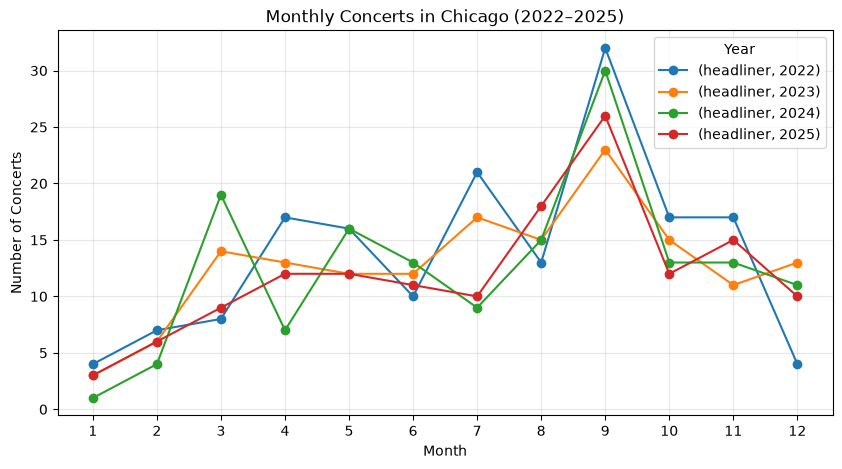

In [39]:
#Concert counts by year and month
concert_monthly = cd_22_25.groupby(["year", "month"])[["headliner"]].count()
concert_monthly = concert_monthly.unstack(level="year")

concert_monthly.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Concerts in Chicago (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Number of Concerts")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()